# Analisis Sentimen
Analisis sentimen adalah teknik dalam Natural Language Processing (NLP) yang bertujuan mengidentifikasi dan mengklasifikasikan opini subjektif dalam bentuk teks (Winahyu & Suharjo, 2021). Pada aplikasi digital, teknik ini membantu mengungkap persepsi pengguna terhadap kemudahan penggunaan, keamanan sistem, dan kualitas layanan secara menyeluruh.

Peningkatan popularitas aplikasi investasi belum sepenuhnya menghilangkan keraguan sebagian masyarakat dalam menggunakannya. Keraguan itu umumnya disebabkan oleh kurangnya pemahaman tentang mekanisme kerja aplikasi serta minimnya informasi mengenai kelebihan dan kekurangannya (Saputra et al., 2021). Ulasan pengguna di Google Play Store menjadi sumber data penting yang mencerminkan pengalaman, tingkat kepuasan, dan persepsi pengguna, sekaligus memengaruhi keputusan calon pengguna (Afifa Lufti Insani et al., 2023).

Jumlah ulasan yang besar membuat pengolahan manual tidak efisien dan berisiko subjektif, sehingga diperlukan pendekatan machine learning untuk mengklasifikasikan sentimen secara otomatis. Berbagai algoritma, seperti Naïve Bayes, Random Forest, Logistic Regression, dan Decision Tree, telah banyak digunakan pada klasifikasi teks, tetapi kinerjanya bergantung pada karakteristik data, terutama ketidakseimbangan kelas. Oleh karena itu, penelitian ini membandingkan beberapa algoritma dalam satu alur (pipeline) yang sama dan seragam, sehingga model terbaik ditentukan dari hasil evaluasi, bukan dari pemilihan di awal.

Referensi : https://jptam.org/index.php/jptam/article/view/27464/18618

PPT :

Rujukan Lexicon : https://github.com/fajri91/InSet

Menurut Azmi,. dkk 2025, tahapan penelitian analisis sentimen adalah sebagai berikut
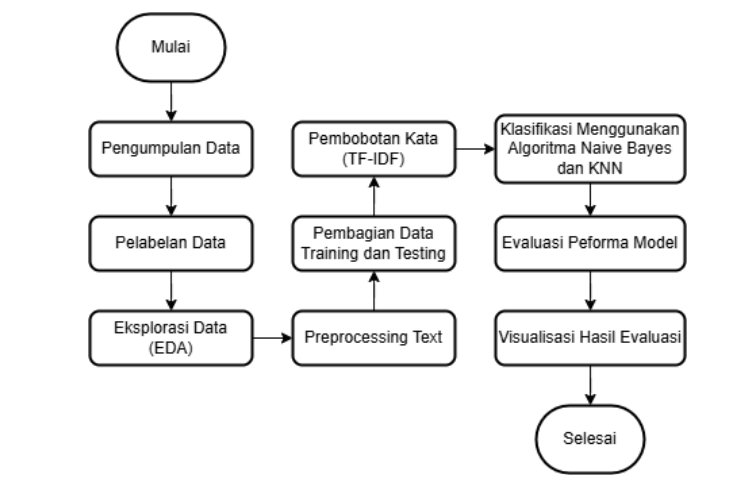

# Scraping Dataset / Pengumpulan Data
adalah proses pengambilan informasi dari website atau sumber digital lainnya secara otomatis untuk dianalisis atau digunakan dalam riset.

In [1]:
# 1. Pemasangan Pustaka
!pip install google-play-scraper
!pip install sastrawi
!pip install wordcloud

# 2. Mengunduh data NLTK
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

# 3. Mengimpor Pustaka Google Play Scraper
from google_play_scraper import reviews_all, reviews, Sort

# Data Manipulation & Analysis
import pandas as pd
import numpy as np
import datetime as dt
import csv
import time
pd.options.mode.chained_assignment = None

# Text Processing (NLP)
import re
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Visualization & ML
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.metrics import accuracy_score

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
import time
# Menggunakan App ID Bibit yang benar
APP_ID = 'com.bibit.bibitid'
TARGET = 5000

print(f"Mulai mengambil ulasan untuk aplikasi: {APP_ID}...")

scrapreview = []
token = None

while len(scrapreview) < TARGET:
    batch, token = reviews(
        APP_ID,
        lang='id',
        country='id',
        sort=Sort.NEWEST,
        count=min(200, TARGET - len(scrapreview)),
        continuation_token=token
    )
    scrapreview.extend(batch)
    print(f"Terkumpul: {len(scrapreview)}")

    if token is None or not batch:   # tidak ada ulasan lagi
        break
    time.sleep(1)

print(f"Selesai! Jumlah ulasan yang berhasil diambil: {len(scrapreview)}")

Mulai mengambil ulasan untuk aplikasi: com.bibit.bibitid...
Terkumpul: 200
Terkumpul: 400
Terkumpul: 600
Terkumpul: 800
Terkumpul: 1000
Terkumpul: 1200
Terkumpul: 1400
Terkumpul: 1600
Terkumpul: 1800
Terkumpul: 2000
Terkumpul: 2200
Terkumpul: 2400
Terkumpul: 2600
Terkumpul: 2800
Terkumpul: 3000
Terkumpul: 3200
Terkumpul: 3400
Terkumpul: 3600
Terkumpul: 3800
Terkumpul: 4000
Terkumpul: 4200
Terkumpul: 4400
Terkumpul: 4600
Terkumpul: 4800
Terkumpul: 5000
Selesai! Jumlah ulasan yang berhasil diambil: 5000


## Simpan Scraping ke CSV

In [3]:
with open('ulasan_bibit.csv', mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerow(['UserName', 'Content', 'at', 'replyContent', 'Score'])

    for review in scrapreview:
        writer.writerow([
            review['userName'],
            review['content'],
            review['at'],
            review['replyContent'],
            review['score'],
        ])

In [4]:
df = pd.read_csv('ulasan_bibit.csv')
display(df.head(5))

,UserName,Content,at,replyContent,Score
0,Waradana Dana,apa sih aplikasi ini saya mau investas di suru...,2026-10-27 03:37:15,"Hai kak, kami mohon maaf atas ketidaknyamanan ...",1
1,RISKA YANTI,sangat membantu,2026-10-27 01:59:20,Terima kasih Kak Riska atas kepercayaan kakak ...,5
2,Puryanto Puryanto,aplikasi bagus dan mudah,2026-10-27 01:27:58,Terima kasih Kak Puryanto telah memilih Bibit ...,5
3,Kevin Dismayana,"sangat bagus ,memberi profit jangka panjang,sa...",2026-10-27 00:54:03,"Halo Kak Kevin, kami senang sekali membaca rev...",5
4,Muhammad Dicky,UI nya sangat nyaman,2026-10-26 22:14:06,"Halo kak, kami senang sekali membaca review po...",5


## Pelabelan Data
Data   yang   telah   dikumpulkan   diberi   label   secara   otomatis   berdasarkan rating pengguna, rating 4  dan  5  dikategorikan  sebagai  sentimen  positif, rating 1  dan  2  sebagai sentimen negatif,  dan rating 3 sebagai  netral.  Untuk meningkatkan  akurasi,  dilakukan validasi manual untuk memastikan kesesuaian antara isi komentar dan rating

In [5]:
# PELABELAN DATA
# Labeling otomatis berdasarkan rating
def label_sentimen(score):
    if score >= 4:
        return 'Positif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Negatif'

df['sentimen'] = df['Score'].apply(label_sentimen)
print("  HASIL PELABELAN OTOMATIS")
print(df[['Content', 'Score', 'sentimen']].head(10).to_string())

  HASIL PELABELAN OTOMATIS
                                                                                                                                                                                                                                                                           Content  Score sentimen
0  apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago terus trusan capek saya harus isi isi data sana sini seharusnya lebih plek siblel mau bang apapun bisa di gunakan pembuat aplikasi otak nya geser membuat saya emosi aja ini lah kebodohan sesungguh nya      1  Negatif
1                                                                                                                                                                                                                                                                  sangat membantu      5  Positif
2                                                                                                   

## Cek Manual Pelabelan

In [6]:
df.head(5)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   UserName      5000 non-null   object
 1   Content       5000 non-null   object
 2   at            5000 non-null   object
 3   replyContent  4973 non-null   object
 4   Score         5000 non-null   int64 
 5   sentimen      5000 non-null   object
dtypes: int64(1), object(5)
memory usage: 234.5+ KB


# Data Understanding


In [7]:
df = df.copy()

In [8]:
# INFO DATASET — jumlah ulasan, kolom yang tersedia
jumlah_ulasan, jumlah_kolom = df.shape

print("  INFO DATASET")
print(f"  Jumlah Ulasan (Baris) : {jumlah_ulasan}")
print(f"  Jumlah Kolom          : {jumlah_kolom}")
print(f"  Nama Kolom            : {list(df.columns)}")

display(df.head(5))
df.info()

  INFO DATASET
  Jumlah Ulasan (Baris) : 5000
  Jumlah Kolom          : 6
  Nama Kolom            : ['UserName', 'Content', 'at', 'replyContent', 'Score', 'sentimen']


,UserName,Content,at,replyContent,Score,sentimen
0,Waradana Dana,apa sih aplikasi ini saya mau investas di suru...,2026-10-27 03:37:15,"Hai kak, kami mohon maaf atas ketidaknyamanan ...",1,Negatif
1,RISKA YANTI,sangat membantu,2026-10-27 01:59:20,Terima kasih Kak Riska atas kepercayaan kakak ...,5,Positif
2,Puryanto Puryanto,aplikasi bagus dan mudah,2026-10-27 01:27:58,Terima kasih Kak Puryanto telah memilih Bibit ...,5,Positif
3,Kevin Dismayana,"sangat bagus ,memberi profit jangka panjang,sa...",2026-10-27 00:54:03,"Halo Kak Kevin, kami senang sekali membaca rev...",5,Positif
4,Muhammad Dicky,UI nya sangat nyaman,2026-10-26 22:14:06,"Halo kak, kami senang sekali membaca review po...",5,Positif


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   UserName      5000 non-null   object
 1   Content       5000 non-null   object
 2   at            5000 non-null   object
 3   replyContent  4973 non-null   object
 4   Score         5000 non-null   int64 
 5   sentimen      5000 non-null   object
dtypes: int64(1), object(5)
memory usage: 234.5+ KB


In [9]:
# RENTANG TANGGAL ULASAN
df['at'] = pd.to_datetime(df['at'], errors='coerce')

tanggal_awal  = df['at'].min()
tanggal_akhir = df['at'].max()

print(f"\n  Rentang Tanggal Ulasan:")
print(f"  Dari  : {tanggal_awal.strftime('%d %B %Y')}")
print(f"  Hingga: {tanggal_akhir.strftime('%d %B %Y')}")


  Rentang Tanggal Ulasan:
  Dari  : 25 March 2025
  Hingga: 27 October 2026


In [10]:
# STATISTIK DESKRIPTIF — distribusi rating, rata-rata, median, modus
print("  STATISTIK DESKRIPTIF KOLOM SCORE (RATING)")

print(df.describe(include="all"))
print(f"\n  Rata-rata Rating : {df['Score'].mean():.2f}")
print(f"  Median Rating    : {df['Score'].median():.0f}")
print(f"  Modus Rating     : {df['Score'].mode()[0]}")

# Rata-rata panjang teks ulasan
df['panjang_ulasan'] = df['Content'].astype(str).str.len()
print(f"\n  Rata-rata panjang teks ulasan : {df['panjang_ulasan'].mean():.0f} karakter")
print(f"  Terpendek                     : {df['panjang_ulasan'].min()} karakter")
print(f"  Terpanjang                    : {df['panjang_ulasan'].max()} karakter")

# Jumlah ulasan yang mendapat balasan dari developer
jumlah_reply = df['replyContent'].notna().sum()
print(f"\n  Ulasan yang dibalas developer : {jumlah_reply} ({jumlah_reply/jumlah_ulasan*100:.1f}%)")

  STATISTIK DESKRIPTIF KOLOM SCORE (RATING)
             UserName Content                             at  \
count            5000    5000                           5000   
unique           4971    3981                            NaN   
top     Budi Setiawan   bagus                            NaN   
freq                3     178                            NaN   
mean              NaN     NaN  2025-12-29 11:06:56.718200064   
min               NaN     NaN            2025-03-25 04:50:42   
25%               NaN     NaN     2025-08-25 04:59:23.500000   
50%               NaN     NaN     2025-12-31 02:06:29.500000   
75%               NaN     NaN     2026-04-20 08:19:48.500000   
max               NaN     NaN            2026-10-27 03:37:15   
std               NaN     NaN                            NaN   

                                             replyContent       Score sentimen  
count                                                4973  5000.00000     5000  
unique                   

/tmp/ipykernel_5995/136281874.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=dist_rating.index, y=dist_rating.values, palette=warna_bintang)


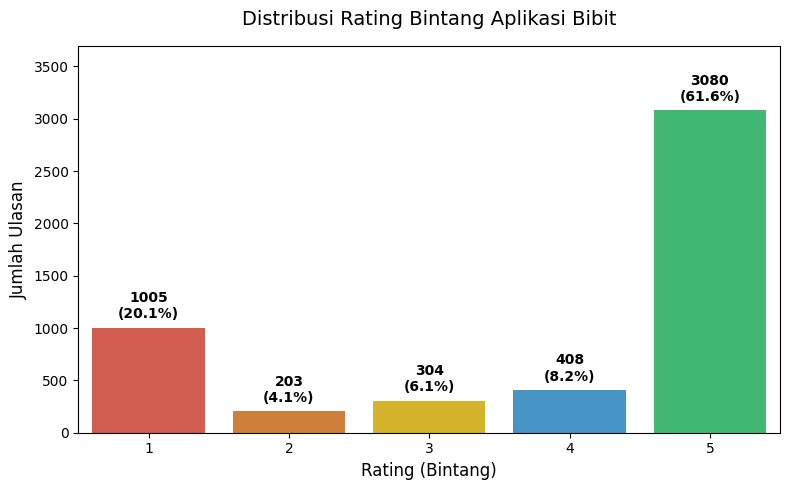

In [38]:
# Visualisasi Distribusi Rating Bintang
# Menyiapkan data (pastikan variabel dist_rating dan jumlah_ulasan sudah terdefinisi)
dist_rating = df['Score'].value_counts().sort_index()

# Menyiapkan canvas
plt.figure(figsize=(8, 5))

# Menentukan warna gradasi (Merah untuk 1, Hijau untuk 5)
warna_bintang = ['#e74c3c', '#e67e22', '#f1c40f', '#3498db', '#2ecc71']

# Membuat bar chart
ax = sns.barplot(x=dist_rating.index, y=dist_rating.values, palette=warna_bintang)

# Beri ruang 20% di atas batang tertinggi agar label tidak menabrak garis
ax.set_ylim(0, max(dist_rating.values) * 1.2)

# Konfigurasi judul dan label
plt.title('Distribusi Rating Bintang Aplikasi Bibit', fontsize=14, pad=15)
plt.xlabel('Rating (Bintang)', fontsize=12)
plt.ylabel('Jumlah Ulasan', fontsize=12)

# Menambahkan anotasi angka dan persentase tepat di atas masing-masing batang
for i, v in enumerate(dist_rating.values):
    persen = (v / jumlah_ulasan) * 100
    # Menampilkan jumlah ulasan dan persentasenya
    ax.text(i, v + (max(dist_rating.values) * 0.02), f"{v}\n({persen:.1f}%)",
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Render grafik
plt.tight_layout()
plt.show()

  DISTRIBUSI SENTIMEN AWAL (berdasarkan rating)
  Positif   :  3488 ulasan (69.8%)
  Negatif   :  1208 ulasan (24.2%)
  Netral    :   304 ulasan (6.1%)


/tmp/ipykernel_5995/975990727.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kategori, y=jumlah_nilai, palette=warna_dinamis, ax=ax1)


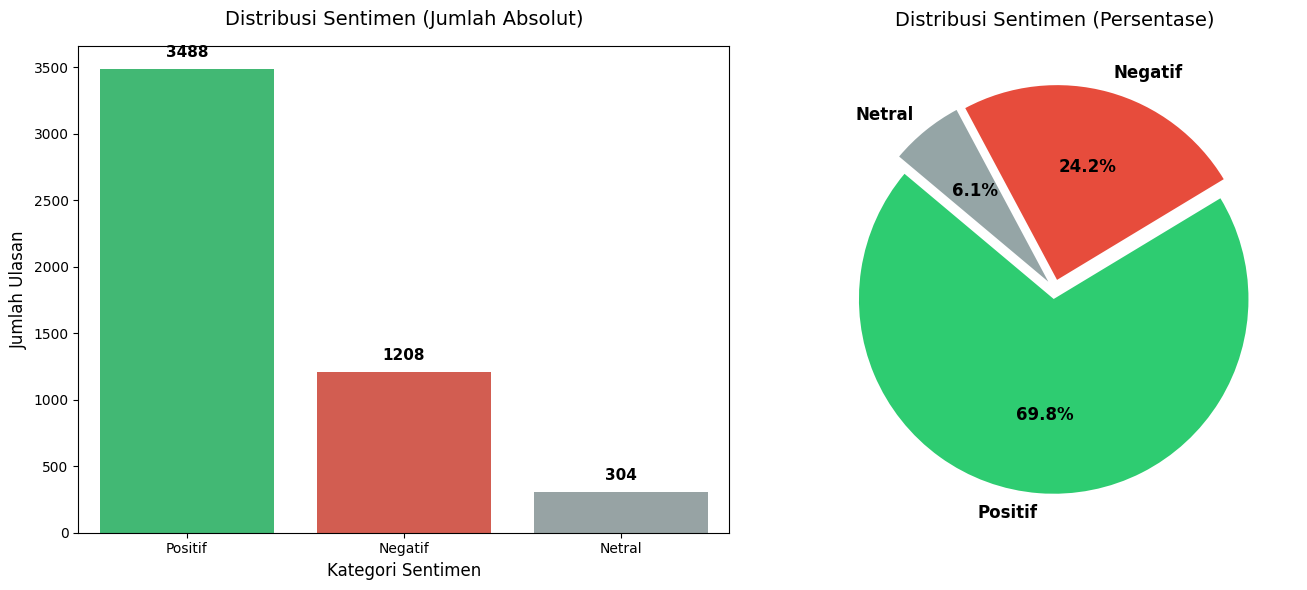

In [12]:
# DISTRIBUSI SENTIMEN AWAL (baseline dari rating)
def label_sentimen(score):
    if score >= 4:
        return 'Positif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Negatif'

df['sentimen_awal'] = df['Score'].apply(label_sentimen)
dist_sentimen = df['sentimen_awal'].value_counts()

print("  DISTRIBUSI SENTIMEN AWAL (berdasarkan rating)")
for sentimen, jumlah in dist_sentimen.items():
    print(f"  {sentimen:<10}: {jumlah:>5} ulasan ({jumlah/len(df)*100:.1f}%)")

# VISUALISASI DATA (GABUNGAN)
# Persiapan Data & Warna Konsisten (Dideklarasikan satu kali saja)
kategori = list(dist_sentimen.index)
jumlah_nilai = list(dist_sentimen.values)

kamus_warna = {
    'Positif': '#2ecc71', # Hijau
    'Negatif': '#e74c3c', # Merah
    'Netral': '#95a5a6'   # Abu-abu
}
# Mencocokkan warna agar Bar dan Pie chart menggunakan warna yang persis sama
warna_dinamis = [kamus_warna[label] for label in kategori]
efek_pecahan = [0.05] * len(kategori) # Membuat jarak otomatis berapapun jumlah kategorinya

# 2. Membuat Canvas dengan 1 Baris dan 2 Kolom (Kiri-Kanan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- GRAFIK KIRI: BAR CHART ---
sns.barplot(x=kategori, y=jumlah_nilai, palette=warna_dinamis, ax=ax1)
ax1.set_title('Distribusi Sentimen (Jumlah Absolut)', fontsize=14, pad=15)
ax1.set_xlabel('Kategori Sentimen', fontsize=12)
ax1.set_ylabel('Jumlah Ulasan', fontsize=12)

# Anotasi teks di atas batang
for i, v in enumerate(jumlah_nilai):
    ax1.text(i, v + (max(jumlah_nilai) * 0.02), str(v),
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# --- GRAFIK KANAN: PIE CHART ---
ax2.pie(jumlah_nilai, labels=kategori, colors=warna_dinamis, autopct='%1.1f%%',
        startangle=140, explode=efek_pecahan,
        textprops={'fontsize': 12, 'fontweight': 'bold'})
ax2.set_title('Distribusi Sentimen (Persentase)', fontsize=14, pad=15)

# 3. Merapikan dan Menampilkan
plt.tight_layout()
plt.show()

In [13]:
# ANALISIS KUALITAS DATA — missing value, duplikat, kosong
print("  ANALISIS KUALITAS DATA")

# Missing value
print("\n  Missing Value per Kolom:")
print(df.isnull().sum().to_string())

# Duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"\n  Jumlah baris duplikat : {jumlah_duplikat}")

# Ulasan kosong / hanya spasi
ulasan_kosong = df['Content'].isna().sum() + \
                (df['Content'].astype(str).str.strip() == '').sum()
print(f"  Ulasan kosong/null    : {ulasan_kosong}")

  ANALISIS KUALITAS DATA

  Missing Value per Kolom:
UserName           0
Content            0
at                 0
replyContent      27
Score              0
sentimen           0
panjang_ulasan     0
sentimen_awal      0

  Jumlah baris duplikat : 0
  Ulasan kosong/null    : 0


In [14]:
print("  KESIMPULAN DATA UNDERSTANDING")
print(f"  Total ulasan terkumpul    : {jumlah_ulasan}")
print(f"  Rentang tanggal           : {tanggal_awal.strftime('%d %b %Y')} – {tanggal_akhir.strftime('%d %b %Y')}")
print(f"  Rating rata-rata          : {df['Score'].mean():.2f} / 5.0")
print(f"  Sentimen positif          : {dist_sentimen.get('Positif', 0)} ({dist_sentimen.get('Positif', 0)/jumlah_ulasan*100:.1f}%)")
print(f"  Sentimen negatif          : {dist_sentimen.get('Negatif', 0)} ({dist_sentimen.get('Negatif', 0)/jumlah_ulasan*100:.1f}%)")
print(f"  Sentimen netral           : {dist_sentimen.get('Netral', 0)} ({dist_sentimen.get('Netral', 0)/jumlah_ulasan*100:.1f}%)")
print(f"  Missing value             : {df.isnull().sum().sum()}")
print(f"  Duplikat                  : {jumlah_duplikat}")
print(f"  Ulasan kosong             : {ulasan_kosong}")
imbalance = dist_sentimen.get('Positif', 0) / max(dist_sentimen.get('Negatif', 1), 1)
print(f"  Rasio Positif:Negatif     : {imbalance:.1f}:1 {'⚠ Class imbalance!' if imbalance > 3 else '✔ Seimbang'}")

  KESIMPULAN DATA UNDERSTANDING
  Total ulasan terkumpul    : 5000
  Rentang tanggal           : 25 Mar 2025 – 27 Oct 2026
  Rating rata-rata          : 3.87 / 5.0
  Sentimen positif          : 3488 (69.8%)
  Sentimen negatif          : 1208 (24.2%)
  Sentimen netral           : 304 (6.1%)
  Missing value             : 27
  Duplikat                  : 0
  Ulasan kosong             : 0
  Rasio Positif:Negatif     : 2.9:1 ✔ Seimbang


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserName        5000 non-null   object        
 1   Content         5000 non-null   object        
 2   at              5000 non-null   datetime64[ns]
 3   replyContent    4973 non-null   object        
 4   Score           5000 non-null   int64         
 5   sentimen        5000 non-null   object        
 6   panjang_ulasan  5000 non-null   int64         
 7   sentimen_awal   5000 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 312.6+ KB


Informasi Dataset

- Total ulasan yang di-scraping: 5.000 (aplikasi Bibit, com.bibit.bibitid, bahasa Indonesia, urutan terbaru).
- Rentang tanggal: 25 Maret 2025 – 27 Oktober 2026.
- Kolom: 6 kolom, yaitu UserName, Content (teks ulasan), at (tanggal), replyContent (balasan developer), Score (rating), dan sentimen (label hasil pelabelan dari rating).
- Nilai kosong: hanya 27, semuanya di replyContent. Kolom lain lengkap. Tidak ada baris duplikat penuh dan tidak ada ulasan kosong.

# Data Preparation


## Menghapus Kolom yang Tidak Diperlukan

In [16]:
# Menghapus kolom yang TIDAK diperlukan
app_reviews_df = df.drop(columns=['at', 'panjang_ulasan', 'sentimen_awal'])

# Menampilkan informasi DataFrame setelah penghapusan kolom untuk verifikasi
print("Informasi DataFrame setelah menghapus kolom yang tidak relevan:")
app_reviews_df.info()

Informasi DataFrame setelah menghapus kolom yang tidak relevan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   UserName      5000 non-null   object
 1   Content       5000 non-null   object
 2   replyContent  4973 non-null   object
 3   Score         5000 non-null   int64 
 4   sentimen      5000 non-null   object
dtypes: int64(1), object(4)
memory usage: 195.4+ KB


## Menghapus Nilai Hilang

In [17]:
# Membuat DataFrame baru (clean_df) dengan menghapus baris yang memiliki nilai yang hilang (NaN)
clean_df = app_reviews_df.dropna(subset=['Content'])
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   UserName      5000 non-null   object
 1   Content       5000 non-null   object
 2   replyContent  4973 non-null   object
 3   Score         5000 non-null   int64 
 4   sentimen      5000 non-null   object
dtypes: int64(1), object(4)
memory usage: 195.4+ KB


## Menghapus Nilai Duplikat

In [18]:
# Menghapus baris duplikat dari DataFrame clean_df
clean_df = clean_df.drop_duplicates()

# Menghitung dan menampilkan jumlah baris dan kolom dalam DataFrame clean_df setelah proses cleaning
jumlah_ulasan_setelah_hapus_duplikat, jumlah_kolom_setelah_hapus_duplikat = clean_df.shape

print("Informasi Pembersihan Data:")
print(f"Jumlah baris setelah cleaning (hapus NaN & duplikat): {jumlah_ulasan_setelah_hapus_duplikat}")
print(f"Jumlah kolom setelah cleaning (hapus NaN & duplikat): {jumlah_kolom_setelah_hapus_duplikat}")

Informasi Pembersihan Data:
Jumlah baris setelah cleaning (hapus NaN & duplikat): 5000
Jumlah kolom setelah cleaning (hapus NaN & duplikat): 5


In [19]:
# Buang ulasan Netral (rating 3) secara eksplisit, lalu encode label biner
clean_df = clean_df[clean_df['sentimen'] != 'Netral'].copy()
clean_df['sentimen_encode'] = clean_df['sentimen'].map({'Positif': 1, 'Negatif': 0})
assert clean_df['sentimen_encode'].notna().all()

print(len(clean_df), clean_df['sentimen'].value_counts().to_dict())

4696 {'Positif': 3488, 'Negatif': 1208}


In [20]:
print(len(clean_df), clean_df['sentimen'].value_counts().to_dict())

4696 {'Positif': 3488, 'Negatif': 1208}


## Preprocessing Text
Tahapan preprocessing  textdilakukan  untuk membersihkan dan menyiapkan  data  teks agar lebih siap untuk analisis sentimen.Proses ini bertujuan untuk meningkatkan kualitas data dan akurasi model pembelajaran mesin

In [21]:
import re
import string
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import nltk
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

True

### Cleaning
Menghapus  karakter  tidak  relevan  seperti  tanda  baca,  angka,  simbol  khusus,  atau  HTML tag untuk membersihkan teks.

In [22]:
emoji_pattern = re.compile(
    "["
    u"\U0001F600-\U0001F64F"
    u"\U0001F300-\U0001F5FF"
    u"\U0001F680-\U0001F6FF"
    u"\U0001F1E0-\U0001F1FF"
    u"\U00002700-\U000027BF"
    u"\U0001F900-\U0001F9FF"
    "]+",
    flags=re.UNICODE
)

def cleaningText(text):
    text = str(text)
    text = re.sub(r'@[A-Za-z0-9]+', '', text)   # hapus mention
    text = re.sub(r'#[A-Za-z0-9]+', '', text)   # hapus hashtag
    text = re.sub(r'RT[\s]', '', text)           # hapus RT
    text = re.sub(r'http\S+|www\S+', '', text)  # hapus URL
    text = re.sub(r'[0-9]+', '', text)           # hapus angka
    text = emoji_pattern.sub('', text)           # hapus emoji
    text = re.sub(r'[^\w\s]', ' ', text)         # tanda baca → spasi
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.replace('\n', ' ')               # newline → spasi
    text = re.sub(r'\s+', ' ', text).strip()     # rapikan spasi
    return text

clean_df['text_clean'] = clean_df['Content'].apply(cleaningText)

print("=" * 60)
print("  HASIL CLEANING")
print("=" * 60)
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {str(clean_df['Content'].iloc[i])[:70]}")
    print(f"       Sesudah : {clean_df['text_clean'].iloc[i][:70]}")
print("=" * 60)

  HASIL CLEANING

  [1] Sebelum : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago
       Sesudah : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago

  [2] Sebelum : sangat membantu
       Sesudah : sangat membantu

  [3] Sebelum : aplikasi bagus dan mudah
       Sesudah : aplikasi bagus dan mudah

  [4] Sebelum : sangat bagus ,memberi profit jangka panjang,saya sudah lama jadi pengg
       Sesudah : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu

  [5] Sebelum : UI nya sangat nyaman
       Sesudah : UI nya sangat nyaman


### Case Folding
Mengubah seluruh huruf menjadi huruf kecil agar data teks menjadi seragam, mengurangi variasi antara kata yang memiliki makna sama

In [23]:
def casefoldingText(text):
    return str(text).lower()

clean_df['text_casefolding'] = clean_df['text_clean'].apply(casefoldingText)

print("  HASIL CASE FOLDING")
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {clean_df['text_clean'].iloc[i][:70]}")
    print(f"       Sesudah : {clean_df['text_casefolding'].iloc[i][:70]}")

  HASIL CASE FOLDING

  [1] Sebelum : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago
       Sesudah : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago

  [2] Sebelum : sangat membantu
       Sesudah : sangat membantu

  [3] Sebelum : aplikasi bagus dan mudah
       Sesudah : aplikasi bagus dan mudah

  [4] Sebelum : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu
       Sesudah : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu

  [5] Sebelum : UI nya sangat nyaman
       Sesudah : ui nya sangat nyaman


### Normalization
Menyeragamkan kata tidak baku menjadi bentuk baku untuk meningkatkan konsistensi teks.

In [24]:
# Load kamus dari GitHub
url      = 'https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv'
kamus_df = pd.read_csv(url)
kamus_normalisasi = dict(zip(kamus_df['slang'], kamus_df['formal']))

print("  KAMUS NORMALISASI BERHASIL DIMUAT")
print(f"  Total kata dalam kamus : {len(kamus_normalisasi):,}")

def fix_slangwords(text):
    kata_list   = str(text).split()
    kata_normal = [kamus_normalisasi.get(kata, kata) for kata in kata_list]
    return ' '.join(kata_normal)

clean_df['text_slangwords'] = clean_df['text_casefolding'].apply(fix_slangwords)

print("\n  HASIL NORMALISASI:")
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {clean_df['text_casefolding'].iloc[i][:70]}")
    print(f"       Sesudah : {clean_df['text_slangwords'].iloc[i][:70]}")

  KAMUS NORMALISASI BERHASIL DIMUAT
  Total kata dalam kamus : 4,331

  HASIL NORMALISASI:

  [1] Sebelum : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago
       Sesudah : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago

  [2] Sebelum : sangat membantu
       Sesudah : sangat membantu

  [3] Sebelum : aplikasi bagus dan mudah
       Sesudah : aplikasi bagus dan mudah

  [4] Sebelum : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu
       Sesudah : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu

  [5] Sebelum : ui nya sangat nyaman
       Sesudah : ui nya sangat nyaman


### Tokenization
Memecah teks menjadi token atau kata-kata terpisah agar lebih mudah dianalisis.

In [25]:
def tokenizingText(text):
    return word_tokenize(str(text))

clean_df['text_tokenizing'] = clean_df['text_slangwords'].apply(tokenizingText)
clean_df['jumlah_token']    = clean_df['text_tokenizing'].apply(len)

print("  HASIL TOKENISASI")
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {clean_df['text_slangwords'].iloc[i][:70]}")
    print(f"       Sesudah : {clean_df['text_tokenizing'].iloc[i][:8]} ...")
    print(f"       Jumlah  : {clean_df['jumlah_token'].iloc[i]} token")

print(f"\n  Rata-rata token : {clean_df['jumlah_token'].mean():.1f} kata")
print(f"  Token terbanyak : {clean_df['jumlah_token'].max()} kata")
print(f"  Token tersedikit: {clean_df['jumlah_token'].min()} kata")

  HASIL TOKENISASI

  [1] Sebelum : apa sih aplikasi ini saya mau investas di suruh membuat akun bank jago
       Sesudah : ['apa', 'sih', 'aplikasi', 'ini', 'saya', 'mau', 'investas', 'di'] ...
       Jumlah  : 47 token

  [2] Sebelum : sangat membantu
       Sesudah : ['sangat', 'membantu'] ...
       Jumlah  : 2 token

  [3] Sebelum : aplikasi bagus dan mudah
       Sesudah : ['aplikasi', 'bagus', 'dan', 'mudah'] ...
       Jumlah  : 4 token

  [4] Sebelum : sangat bagus memberi profit jangka panjang saya sudah lama jadi penggu
       Sesudah : ['sangat', 'bagus', 'memberi', 'profit', 'jangka', 'panjang', 'saya', 'sudah'] ...
       Jumlah  : 18 token

  [5] Sebelum : ui nya sangat nyaman
       Sesudah : ['ui', 'nya', 'sangat', 'nyaman'] ...
       Jumlah  : 4 token

  Rata-rata token : 10.2 kata
  Token terbanyak : 87 kata
  Token tersedikit: 0 kata


### Stopword Removal
Menghapus kata-kata umum yang tidak memiliki makna signifikan dalam analisis,

In [26]:
def filteringText(text):
    # Stopwords bahasa Indonesia dan Inggris
    list_stopwords = set(stopwords.words('indonesian'))
    list_stopwords.update(set(stopwords.words('english')))

    # Stopwords custom — kata umum di ulasan Play Store
    # yang tidak memberi makna sentimen
    custom_stop = {
        'iya', 'yaa', 'gak', 'nya', 'na', 'sih', 'ku',
        'di',  'ga',  'ya',  'gaa', 'loh', 'kah', 'woi',
        'woii','woy', 'bibit', 'app', 'apk', 'aplikasi',
        'update', 'google', 'play', 'store', 'versi',
    }
    list_stopwords.update(custom_stop)

    filtered = [kata for kata in text if kata not in list_stopwords]
    return filtered

clean_df['text_stopword'] = clean_df['text_tokenizing'].apply(filteringText)

print("  HASIL STOPWORD REMOVAL")
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {clean_df['text_tokenizing'].iloc[i][:8]} ...")
    print(f"       Sesudah : {clean_df['text_stopword'].iloc[i][:8]} ...")
    sebelum = len(clean_df['text_tokenizing'].iloc[i])
    sesudah = len(clean_df['text_stopword'].iloc[i])
    print(f"       Tereduksi: {sebelum} → {sesudah} token (-{sebelum - sesudah})")

  HASIL STOPWORD REMOVAL

  [1] Sebelum : ['apa', 'sih', 'aplikasi', 'ini', 'saya', 'mau', 'investas', 'di'] ...
       Sesudah : ['investas', 'suruh', 'akun', 'bank', 'jago', 'trusan', 'capek', 'isi'] ...
       Tereduksi: 47 → 20 token (-27)

  [2] Sebelum : ['sangat', 'membantu'] ...
       Sesudah : ['membantu'] ...
       Tereduksi: 2 → 1 token (-1)

  [3] Sebelum : ['aplikasi', 'bagus', 'dan', 'mudah'] ...
       Sesudah : ['bagus', 'mudah'] ...
       Tereduksi: 4 → 2 token (-2)

  [4] Sebelum : ['sangat', 'bagus', 'memberi', 'profit', 'jangka', 'panjang', 'saya', 'sudah'] ...
       Sesudah : ['bagus', 'profit', 'jangka', 'pengguna', 'beli', 'aset'] ...
       Tereduksi: 18 → 6 token (-12)

  [5] Sebelum : ['ui', 'nya', 'sangat', 'nyaman'] ...
       Sesudah : ['ui', 'nyaman'] ...
       Tereduksi: 4 → 2 token (-2)


### Stemming
Mengubah kata berimbuhan menjadi bentuk dasarnya untuk menyederhanakan variasi kata dalam teks.

In [27]:
factory   = StemmerFactory()
stemmer   = factory.create_stemmer()
stem_cache = {}   # cache agar kata yang sama tidak di-stem ulang

def toSentence(list_words):
    return ' '.join(word for word in list_words)

def stem_dengan_cache(kalimat):
    hasil_kata = []
    for kata in str(kalimat).split():
        if kata not in stem_cache:
            stem_cache[kata] = stemmer.stem(kata)
        hasil_kata.append(stem_cache[kata])
    return ' '.join(hasil_kata)

# Gabungkan token → string dulu sebelum stemming
clean_df['text_to_stem'] = clean_df['text_stopword'].apply(toSentence)
print("  MEMULAI STEMMING (menggunakan cache)...")

clean_df['text_stemmed'] = clean_df['text_to_stem'].apply(stem_dengan_cache)
clean_df['text_akhir']   = clean_df['text_stemmed']

print("  Stemming selesai!")
print("\n  HASIL STEMMING:")
for i in range(min(5, len(clean_df))):
    print(f"\n  [{i+1}] Sebelum : {clean_df['text_to_stem'].iloc[i][:70]}")
    print(f"       Sesudah : {clean_df['text_stemmed'].iloc[i][:70]}")

  MEMULAI STEMMING (menggunakan cache)...
  Stemming selesai!

  HASIL STEMMING:

  [1] Sebelum : investas suruh akun bank jago trusan capek isi isi data plek siblel ba
       Sesudah : investas suruh akun bank jago trusan capek isi isi data plek siblel ba

  [2] Sebelum : membantu
       Sesudah : bantu

  [3] Sebelum : bagus mudah
       Sesudah : bagus mudah

  [4] Sebelum : bagus profit jangka pengguna beli aset
       Sesudah : bagus profit jangka guna beli aset

  [5] Sebelum : ui nyaman
       Sesudah : ui nyaman


In [28]:
print("\n" + "=" * 60)
print("  RINGKASAN HASIL PREPROCESSING")
print("=" * 60)
display(clean_df[[
    'Content',
    'text_clean',
    'text_casefolding',
    'text_slangwords',
    'text_tokenizing',
    'text_stopword',
    'text_stemmed',
    'text_akhir'
]].head())

print(f"\n  Total data diproses : {len(clean_df):,} ulasan")
print(f"  Kolom teks final    : 'text_akhir'")
print(f"  Cache stemming      : {len(stem_cache):,} kata unik tersimpan")
print("=" * 60)


  RINGKASAN HASIL PREPROCESSING


,Content,text_clean,text_casefolding,text_slangwords,text_tokenizing,text_stopword,text_stemmed,text_akhir
0,apa sih aplikasi ini saya mau investas di suru...,apa sih aplikasi ini saya mau investas di suru...,apa sih aplikasi ini saya mau investas di suru...,apa sih aplikasi ini saya mau investas di suru...,"[apa, sih, aplikasi, ini, saya, mau, investas,...","[investas, suruh, akun, bank, jago, trusan, ca...",investas suruh akun bank jago trusan capek isi...,investas suruh akun bank jago trusan capek isi...
1,sangat membantu,sangat membantu,sangat membantu,sangat membantu,"[sangat, membantu]",[membantu],bantu,bantu
2,aplikasi bagus dan mudah,aplikasi bagus dan mudah,aplikasi bagus dan mudah,aplikasi bagus dan mudah,"[aplikasi, bagus, dan, mudah]","[bagus, mudah]",bagus mudah,bagus mudah
3,"sangat bagus ,memberi profit jangka panjang,sa...",sangat bagus memberi profit jangka panjang say...,sangat bagus memberi profit jangka panjang say...,sangat bagus memberi profit jangka panjang say...,"[sangat, bagus, memberi, profit, jangka, panja...","[bagus, profit, jangka, pengguna, beli, aset]",bagus profit jangka guna beli aset,bagus profit jangka guna beli aset
4,UI nya sangat nyaman,UI nya sangat nyaman,ui nya sangat nyaman,ui nya sangat nyaman,"[ui, nya, sangat, nyaman]","[ui, nyaman]",ui nyaman,ui nyaman



  Total data diproses : 4,696 ulasan
  Kolom teks final    : 'text_akhir'
  Cache stemming      : 3,884 kata unik tersimpan


In [29]:
print(len(clean_df), clean_df['sentimen'].value_counts().to_dict())

4696 {'Positif': 3488, 'Negatif': 1208}


## TF-IDF
Data teks kemudian diubah menjadi representasi numerik menggunakan metode Term Frequency-Inverse  Document  Frequency(TF-IDF).  Metode  ini  memberikan  bobot pada  setiap kata berdasarkan frekuensinya dalam dokumen dan kelangkaannya dalam seluruh korpus. TF-IDF berguna untuk menilai pentingnya suatu kata dalam dokumen tertentu, di mana kata yang sering muncul  dalam  dokumen  tetapi  jarang di  dokumen  lain  diberi  bobot  lebih  tinggi

In [30]:
# Netral sudah dibuang di tahap sebelumnya, pastikan label tidak ada NaN
X_text = clean_df['text_akhir']
y = clean_df['sentimen_encode'].astype(int).values

print(f"Jumlah dokumen : {len(X_text):,}")
print(f"Positif (1)    : {(y == 1).sum()} ({(y == 1).mean()*100:.1f}%)")
print(f"Negatif (0)    : {(y == 0).sum()} ({(y == 0).mean()*100:.1f}%)")

Jumlah dokumen : 4,696
Positif (1)    : 3488 (74.3%)
Negatif (0)    : 1208 (25.7%)


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

def buat_tfidf():
    return TfidfVectorizer(
        max_features=5000,   # maksimal 5000 fitur terpenting
        ngram_range=(1, 2),  # unigram + bigram
        min_df=2,            # abaikan kata yang muncul di < 2 dokumen
        sublinear_tf=True,   # log(tf) agar kata sangat sering tidak mendominasi
    )

# Contoh: fit hanya pada data latih (80:20), transform pada data uji
X_tr, X_te, y_tr, y_te = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

tfidf_contoh = buat_tfidf()
X_tr_tfidf = tfidf_contoh.fit_transform(X_tr)   # fit + transform: data latih
X_te_tfidf = tfidf_contoh.transform(X_te)       # transform saja: data uji

print("HASIL TF-IDF (contoh split 80:20)")
print(f"Shape data latih : {X_tr_tfidf.shape}")
print(f"Shape data uji   : {X_te_tfidf.shape}")
print(f"Jumlah fitur     : {len(tfidf_contoh.get_feature_names_out()):,}")

# Top 20 kata dengan bobot TF-IDF tertinggi (dari data latih)
fitur = tfidf_contoh.get_feature_names_out()
bobot = np.asarray(X_tr_tfidf.sum(axis=0)).flatten()
top20 = bobot.argsort()[::-1][:20]

print("\nTop 20 kata berdasarkan total bobot TF-IDF:")
for i, idx in enumerate(top20, 1):
    print(f"{i:>2}. {fitur[idx]:<25} {bobot[idx]:.4f}")

HASIL TF-IDF (contoh split 80:20)
Shape data latih : (3756, 2658)
Shape data uji   : (940, 2658)
Jumlah fitur     : 2,658

Top 20 kata berdasarkan total bobot TF-IDF:
 1. bagus                     360.1081
 2. mantap                    189.2147
 3. good                      137.9125
 4. investasi                 90.6570
 5. mudah                     83.1823
 6. ok                        80.9050
 7. mula                      75.9542
 8. bantu                     67.6353
 9. banget                    67.4723
10. buka                      61.3917
11. baik                      59.4228
12. keren                     53.5162
13. ajar                      46.5192
14. masuk                     40.4583
15. verifikasi                40.4154
16. oke                       40.2334
17. uang                      37.1768
18. cair                      37.1223
19. moga                      36.6015
20. aman                      34.5739


In [32]:
# pipe = Pipeline([('tfidf', buat_tfidf()), ('clf', clf)])

## WORD CLOUD

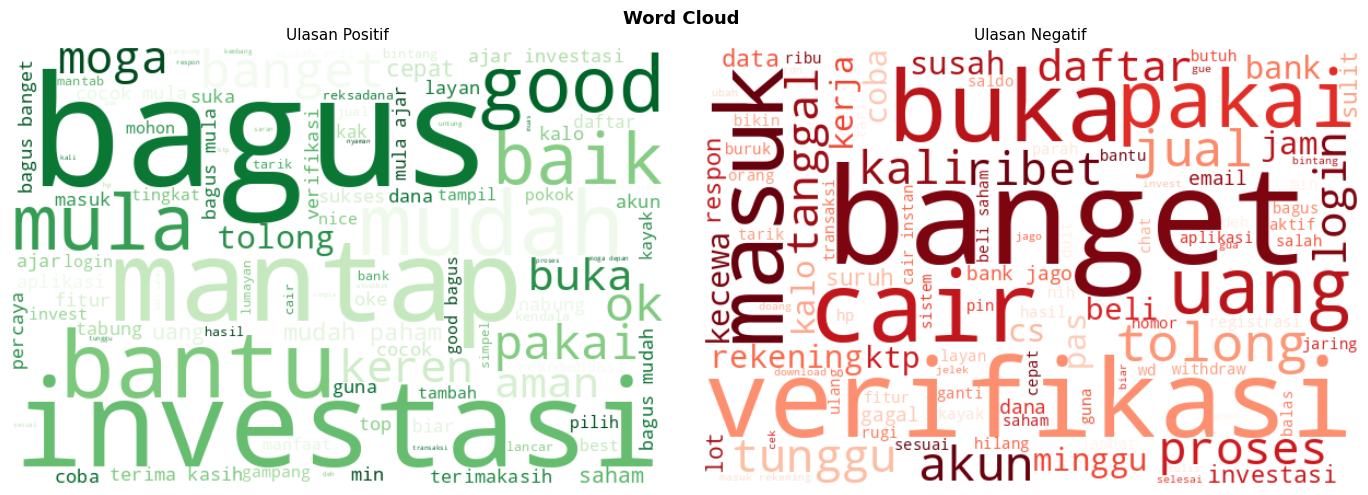

In [33]:
# WORD CLOUD SETELAH PREPROCESSING
teks_pos = ' '.join(clean_df[clean_df['sentimen_encode'] == 1]['text_akhir'])
teks_neg = ' '.join(clean_df[clean_df['sentimen_encode'] == 0]['text_akhir'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Word Cloud ', fontsize=13, fontweight='bold')

WordCloud(width=600, height=400, background_color='white',
          colormap='Greens', max_words=100).generate(teks_pos).to_image()
wc_pos = WordCloud(width=600, height=400, background_color='white',
                   colormap='Greens', max_words=100).generate(teks_pos)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Ulasan Positif', fontsize=11)
axes[0].axis('off')

wc_neg = WordCloud(width=600, height=400, background_color='white',
                   colormap='Reds', max_words=100).generate(teks_neg)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Ulasan Negatif', fontsize=11)
axes[1].axis('off')

plt.tight_layout()
plt.savefig('wordcloud_setelah_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()

# Modelling

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

def tfidf():
    return TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                           min_df=2, sublinear_tf=True)

models = {
    'Naive Bayes': MultinomialNB(fit_prior=False),   # prior seimbang
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
}

rekap = []
for test_size, label in [(0.4,'60:40'),(0.3,'70:30'),(0.2,'80:20'),(0.1,'90:10')]:
    Xtr, Xte, ytr, yte = train_test_split(
        X_text, y, test_size=test_size, random_state=42, stratify=y)
    for nama, clf in models.items():
        pipe = Pipeline([('tfidf', tfidf()), ('clf', clf)])
        pipe.fit(Xtr, ytr)
        yp = pipe.predict(Xte)
        tn, fp, fn, tp = confusion_matrix(yte, yp).ravel()
        rekap.append({
            'Rasio': label, 'Algoritma': nama,
            'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
            'Akurasi (%)': round(accuracy_score(yte, yp)*100, 2),
            'Recall Positif (%)': round(recall_score(yte, yp, pos_label=1)*100, 2),
            'Recall Negatif (%)': round(recall_score(yte, yp, pos_label=0)*100, 2),
            'Presisi Macro (%)': round(precision_score(yte, yp, average='macro')*100, 2),
            'Recall Macro (%)': round(recall_score(yte, yp, average='macro')*100, 2),
            'F1 Macro (%)': round(f1_score(yte, yp, average='macro')*100, 2),
        })
display(pd.DataFrame(rekap))

,Rasio,Algoritma,TP,FP,TN,FN,Akurasi (%),Recall Positif (%),Recall Negatif (%),Presisi Macro (%),Recall Macro (%),F1 Macro (%)
0,60:40,Naive Bayes,1123,21,462,273,84.35,80.44,95.65,80.51,88.05,82.14
1,60:40,Random Forest,1273,89,394,123,88.72,91.19,81.57,84.84,86.38,85.56
2,60:40,Logistic Regression,1231,39,444,165,89.14,88.18,91.93,84.92,90.05,86.83
3,60:40,Decision Tree,1278,114,369,118,87.65,91.55,76.40,83.79,83.97,83.88
4,70:30,Naive Bayes,845,17,345,202,84.46,80.71,95.30,80.55,88.01,82.22
5,70:30,Random Forest,950,66,296,97,88.43,90.74,81.77,84.41,86.25,85.25
6,70:30,Logistic Regression,929,33,329,118,89.28,88.73,90.88,85.09,89.81,86.91
7,70:30,Decision Tree,945,82,280,102,86.94,90.26,77.35,82.66,83.80,83.20
8,80:20,Naive Bayes,570,11,231,128,85.21,81.66,95.45,81.23,88.56,83.00
9,80:20,Random Forest,637,41,201,61,89.15,91.26,83.06,85.34,87.16,86.17


# Intepretasi

Pola yang konsisten: Logistic Regression dan Random Forest, Naive Bayes paling rendah, dan Decision Tree di tengah.

Penelitian ini mengklasifikasikan sentimen 4.696 ulasan aplikasi Bibit (3.488 positif atau 74,3%, dan 1.208 negatif atau 25,7%) setelah ulasan netral dikeluarkan. Karena distribusi kelas tidak seimbang, evaluasi dititikberatkan pada F1-Score macro dan recall per kelas, bukan pada akurasi saja. Pembobotan TF-IDF dilakukan hanya pada data latih untuk menghindari kebocoran data, dan ketidakseimbangan kelas ditangani dengan class_weight='balanced' (Random Forest, Logistic Regression, Decision Tree) serta fit_prior=False (Naïve Bayes).

Kinerja Kelas

Keempat model tidak lagi condong ke satu kelas, tetapi karakternya berbeda:

- Naïve Bayes sangat baik mengenali kelas negatif (recall 95,30–96,69%) tetapi lebih lemah mengenali kelas positif (recall 80,44–83,09%).
- Random Forest dan Decision Tree sebaliknya, lebih sensitif terhadap kelas positif (recall 90,26–93,41%) dengan recall negatif yang lebih rendah (Random Forest 81,57–84,30%, Decision Tree 76,40–78,93%). Artinya keduanya lebih sering salah mmemberikan ulasan negatif sebagai positif.
- Logistic Regression paling seimbang: recall positif 88,18–89,68% dan recall negatif 90,88–93,39%.

Karena tujuan analisis sentimen adalah mengenali keluhan pengguna (kelas negatif) dengan baik tanpa mengorbankan kelas positif, keseimbangan ini membuat Logistic Regression menjadi model baik.

Pengaruh rasio pembagian data

Secara umum, kinerja cenderung naik seiring bertambahnya porsi data latih, terutama pada Random Forest (F1 macro 85,56% pada 60:40 menjadi 88,44% pada 90:10). Perlu diperhatikan bahwa pada rasio 90:10 data uji hanya terdiri dari 470 ulasan (±121 ulasan negatif), sehingga selisih kecil antar model pada rasio ini (misalnya Random Forest 88,44% dengan Logistic Regression 88,00%) belum dapat dianggap perbedaan yang bermakna. Perbandingan 80:20 merupakan jalan tengah dalam membagi data latih dan data uji.

Kesimpulan

Logistic Regression dipilih sebagai model terbaik karena kinerjanya konsisten di semua rasio dan seimbang antar kelas (F1 macro hingga 88,00%). Random Forest merupakan alternatif yang kompetitif dengan F1 macro tertinggi pada rasio 90:10 (88,44%). Naïve Bayes dapat dipakai sebagai pembanding dasar karena komputasinya ringan, tetapi kurang sensitif terhadap kelas positif.